# LASSI - Power Efficiency

***OLLAMA API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [95]:
# Import LASSI modules
import lassi.pipeline
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary


# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1
    
# We need to reload the prompt dictionary because it is under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
# %aimport lassi.getpower
# %aimport lassi.llmconfig
# %aimport lassi.llmmethods
# %aimport lassi.tokenanalysis
# %aimport lassi.code_manager
%aimport lassi.pipeline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [96]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [97]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.

    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]
    """
    
    app_folder_name = "lid-driven-cavity"

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    if source_lang == "CUDA":
        code_compiler = "nvcc"
        code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
        # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM LMSTUDIO
    # model = "lmstudio-community/Meta-Llama-3-8B-Instruct-GGUF/"
    # model = "TheBloke/CodeLlama-13B-Instruct-GGUF"
    # model = "lmstudio-community/starcoder2-15b-instruct-v0.1-GGUF" - couldn;t generate anything
    # model = "lmstudio-community/stable-code-instruct-3b-GGUF" - couldn't compile, but 'worked'
    # model = "microsoft/Phi-3-mini-4k-instruct-gguf" - generated garbage, and slow
    # model = "lmstudio-community/codegemma-1.1-7b-it-GGUF" - generated code, faster, but not compiled -- more tries
    # model = "lmstudio-community/Codestral-22B-v0.1-GGUF"  # - nice large context size 32768 -- load it on aiop01 at 28 gpu layers

    # -- FROM OLLAMA
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model = "deepseek-coder-v2"  # (max token = 16384)
    # model = "codestral"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    model = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 131072

    # ASSIGN LLM API SOURCE:
    if "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "01test_betterpower_withcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llmconfig.unload_ollama_model(model)

    return (app_folder_name, source_lang, target_lang, model, num_ctx, llm_source, use_context,
            context_knowledge_selection, code_compiler, code_compiler_kwds, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


Unloading Ollama server...

Unload LLM:
 {"model":"qwen2.5-coder:32b","created_at":"2025-01-12T20:16:18.906354662Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   171  100   124  100    47  45588  17279 --:--:-- --:--:-- --:--:-- 85500


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: ollama
Model: qwen2.5-coder:32b
System Prompt Index: CUDA
Code file template: generated_codes/ollama_qwen2.5-coder:32b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext

LLM System Prompt: 

You are a professional coding AI assistant that specializes in refactoring parallelized code to improve energy efficiency by reducing GPU and CPU power consumpt

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 15/15 [00:15<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 10.113209 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


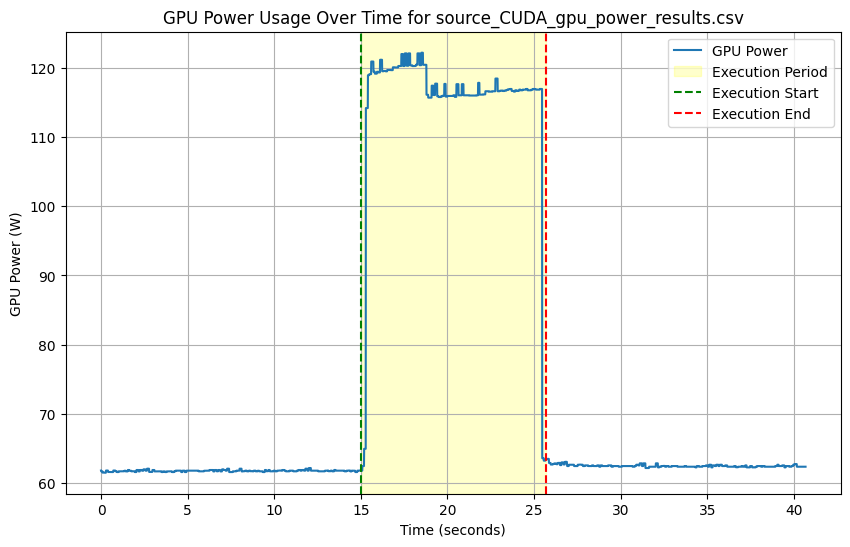

Start time: 15.015 -- End time: 25.668

... Capturing baseline energy consumed for same duration...
Pipeline error | An error occurred: name 'lassi' is not defined

Program executed successfully!





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----




----- CONTEXT KNOWLEDGE SUMMARY -----
(generated by the LLM)



Certainly! Here's a summary of key CUDA optimization strategies based on the provided context:

### High Priority Optimizations

1. **Minimize Global Memory Usage:**
   - Prefer shared memory access over global memory whenever possible, as accessing global memory incurs significant latency.
   - Example:
     ```cpp
     __shared__ float shared[32];
     __device__ float device[32];
     shared[threadIdx.x] = device[threadIdx.x]; // Shared memory is faster than global memory
     ```

2. **Avoid Warp Divergence:**
   - Ensure that threads within the same warp follow similar execution paths to avoid divergence.
   - Example:
     ```cpp
     if (threadIdx.x / WSIZE == someCondition) {
         // All threads in a warp will execute this block or skip it together
     }
     ```
   - Use `__syncwarp()` to ensure that the warp has reconverged before subsequent instructions.

### Medium Priority Optimizations

1. **Optimize Control Flow:**
   - Minimize different execution paths within the same warp by aligning control flow with warp boundaries.
   - Example:
     ```cpp
     if (threadIdx.x % WSIZE == 0) {
         // This condition will be true for one thread per warp, minimizing divergence
     }
     ```

2. **Use Branch Predication:**
   - Encourage the compiler to use branch predication instead of actual branches for small control flow blocks.
   - Example:
     ```cpp
     if (condition) {
         // Small block of instructions that can be predicated
     }
     ```
   - Use `#pragma unroll` to control loop unrolling and potentially enable branch predication.

### Low Priority Optimizations

1. **Loop Unrolling:**
   - Manually control loop unrolling using `#pragma unroll` to optimize performance.
   - Example:
     ```cpp
     #pragma unroll 4
     for (int i = 0; i < N; ++i) {
         // Loop body
     }
     ```

2. **Use Efficient Math Functions:**
   - Replace generic math functions with more efficient alternatives when possible.
   - Example:
     ```cpp
     sinpi(x); // More efficient than sin(PI * x)
     cbrt(x);  // Faster than pow(x, 1/3)
     ```

### Additional Tips

- **Use Efficient Data Types:**
  - Prefer single-precision floating-point (`float`) over double-precision (`double`) for better performance.
  
- **Optimize Memory Access Patterns:**
  - Ensure coalesced memory access patterns to maximize throughput and minimize latency.

- **Leverage CUDA Libraries:**
  - Use optimized CUDA libraries like cuBLAS, cuFFT, etc., for common operations.

By following these optimization strategies, you can significantly improve the performance of your CUDA applications.



----- CODE DESCRIPTION -----
(generated by the LLM)



Your code is a well-structured implementation of the Navier-Stokes equations using CUDA for GPU acceleration. Here are some suggestions and improvements that can be made to enhance readability, performance, and maintainability:

### General Suggestions

1. **Code Organization**:
   - Break down the main function into smaller functions. This will make it easier to read and understand.
   - Use consistent naming conventions.

2. **Error Checking**:
   - Add CUDA error checking after each CUDA API call to catch any issues early on.

3. **Memory Management**:
   - Ensure that all allocated memory is freed in case of an error during execution.

4. **Comments and Documentation**:
   - Add comments explaining the purpose of each function and significant blocks of code.
   - Consider adding a README file with instructions on how to compile and run the code.

5. **Performance Optimization**:
   - Profile your code using tools like NVIDIA Nsight Systems or Nsight Compute to identify bottlenecks.
   - Optimize memory access patterns to improve coalesced memory accesses.

### Specific Suggestions

1. **Error Checking**:
   ```c
   #define CUDA_CHECK(call) \
       do { \
           cudaError_t err = call; \
           if (err != cudaSuccess) { \
               fprintf(stderr, "CUDA error at %s:%d: %s\n", __FILE__, __LINE__, cudaGetErrorString(err)); \
               exit(EXIT_FAILURE); \
           } \
       } while(0)
   ```

2. **Memory Allocation**:
   - Use `cudaMallocManaged` for Unified Memory if your GPU supports it, which can simplify memory management.

3. **Kernel Launch Configuration**:
   - Ensure that the grid and block dimensions are optimal for your specific GPU architecture.
   - Consider using dynamic parallelism if supported by your GPU to further optimize performance.

4. **Boundary Conditions**:
   - The boundary condition setting in `set_BCs` should be optimized to ensure coalesced memory access.

5. **File Writing**:
   - Use binary file writing for large datasets to improve performance.
   - Consider using libraries like HDF5 for more efficient data storage and retrieval.

6. **Code Refactoring**:
   - Move repetitive code into separate functions, such as the loop that calculates `max_u` and `max_v`.

### Example of Error Checking

Here's an example of how you can add error checking to your CUDA calls:

```c
CUDA_CHECK(cudaMalloc(&u_d, size * sizeof(Real)));
CUDA_CHECK(cudaMemcpy(u_d, u, size * sizeof(Real), cudaMemcpyHostToDevice));
```

### Example of Refactoring

You can refactor the loop that calculates `max_u` and `max_v` into a separate function:

```c
void update_max_values(Real* max_arr, Real* max_val, int size) {
    for (int i = 0; i < size; ++i) {
        *max_val = fmax(*max_val, max_arr[i]);
    }
}

// In the main loop:
update_max_values(max_u_arr, &max_u, size_max);
update_max_values(max_v_arr, &max_v, size_max);
```

### Example of Unified Memory

If your GPU supports Unified Memory, you can simplify memory management:

```c
Real *u_d, *v_d, *F_d, *G_d, *pres_red_d, *pres_black_d;
CUDA_CHECK(cudaMallocManaged(&u_d, size * sizeof(Real)));
CUDA_CHECK(cudaMallocManaged(&v_d, size * sizeof(Real)));
// Allocate other arrays similarly

// No need to manually copy data between host and device
```

By implementing these suggestions, you can improve the quality and performance of your code.



----- STARTING CODE GENERATION PIPELINE -----




----- GENERATED CODE -----




The provided code is a C program that simulates fluid flow using the Navier-Stokes equations, specifically solving for velocity and pressure fields on a grid. The simulation uses CUDA to leverage GPU acceleration. Here's a breakdown of the key components and steps in the code:

### Key Components

1. **Initialization**:
   - Memory allocation for arrays representing velocities (`u`, `v`), fluxes (`F`, `G`), pressures (`pres_red`, `pres_black`), residuals, and maximum velocity values.
   - Setting initial conditions and boundary conditions.

2. **Time Loop**:
   - The main simulation loop iterates over time steps until a specified end time is reached.
   - Within each time step, the following sub-steps are performed:

3. **Pressure Calculation (SOR Iterations)**:
   - Calculate the pressure field using Successive Over-Relaxation (SOR) iterations to solve the Poisson equation derived from the continuity equation.
   - Compute residuals and check for convergence based on a tolerance level.

4. **Velocity Update**:
   - Update velocity fields (`u`, `v`) using the computed pressure gradients.
   - Recalculate maximum velocities to adjust time step size if necessary.

5. **Boundary Conditions**:
   - Apply boundary conditions to ensure physical constraints are met at grid boundaries.

6. **Output**:
   - After completing all iterations, write the final velocity field to a file for visualization or further analysis.

7. **Cleanup**:
   - Free allocated memory on both host and device to prevent memory leaks.

### Key Points

- **CUDA Kernels**: The code uses several CUDA kernels (`calculate_u`, `calculate_v`, `red_kernel`, `black_kernel`, etc.) to perform computations in parallel on the GPU.
- **Memory Management**: Proper allocation and deallocation of memory on both host and device are crucial for efficient execution and avoiding memory leaks.
- **Performance Considerations**: The use of shared memory, coalesced global memory access patterns, and minimizing data transfers between host and device can significantly improve performance.

### Potential Improvements

1. **Optimize Memory Access**:
   - Ensure that memory accesses in CUDA kernels are coalesced to maximize throughput.
   - Use shared memory to store frequently accessed data within a block to reduce global memory latency.

2. **Kernel Fusion**:
   - Combine multiple small kernels into larger ones if possible, reducing the overhead of kernel launches and improving occupancy.

3. **Load Balancing**:
   - Ensure that work is evenly distributed across threads and blocks to avoid idle threads and maximize GPU utilization.

4. **Profiling and Tuning**:
   - Use CUDA profiling tools (e.g., NVIDIA Nsight Systems, Nsight Compute) to identify bottlenecks and optimize performance.
   - Experiment with different block sizes and grid configurations to find the optimal configuration for your specific hardware.

5. **Error Handling**:
   - Add error checking after each CUDA API call to catch and handle errors early in the execution process.

By addressing these points, you can further enhance the performance and reliability of the simulation code.

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/ollama_qwen2.5-coder:32b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu', '-o', 'generated_codes/ollama_qwen2.5-coder:32b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext']

***** Compilation failed.
 Error message: 
/usr/bin/ld: /usr/lib/gcc/aarch64-linux-gnu/11/../../../aarch64-linux-gnu/Scrt1.o: in function `_start':
(.text+0x1c): undefined reference to `main'
/usr/bin/ld: (.text+0x20): undefined reference to `main'
collect2: error: ld returned 1 exit status


Execute file: generated_codes/ollama_qwen2.5-coder:32b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext


----- SELF-CORRECTION: 1 -----


----- ERROR SELF-CORRECTION -----

PROMPT (error correction, token count: 7953): [BEGIN CONTEXT KNOWLEDGE] [BEGIN GENERAL CUDA PROGRAMMING 

```c
#include <iostream>
#include <cuda_runtime.h>

#define CUDA_CHECK(call) \
    do { \
        cudaError_t err = call; \
        if (err != cudaSuccess) { \
            fprintf(stderr, "CUDA error at %s:%d: %s\n", __FILE__, __LINE__, cudaGetErrorString(err)); \
            exit(EXIT_FAILURE); \
        } \
    } while(0)

typedef double Real;

__global__ void compute_kernel(Real* u_d, Real* v_d, int size) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < size) {
        // Example computation
        u_d[idx] += v_d[idx];
    }
}

void update_max_values(Real* max_arr, Real* max_val, int size) {
    for (int i = 0; i < size; ++i) {
        *max_val = fmax(*max_val, max_arr[i]);
    }
}

void set_BCs(Real* u_d, Real* v_d, int nx, int ny) {
    // Example boundary condition setting
    for (int j = 0; j < ny; ++j) {
        u_d[j * nx] = 0.0;
        u_d[j * nx + nx - 1] = 0.0;
        v_d[j * nx] = 0.0;
        v_d[j * nx + nx - 1] = 0.0;
    }
    for (int i = 0; i < nx; ++i) {
        u_d[i] = 0.0;
        u_d[(ny - 1) * nx + i] = 0.0;
        v_d[i] = 0.0;
        v_d[(ny - 1) * nx + i] = 0.0;
    }
}

int main(int argc, char* argv[]) {
    int nx = 256;
    int ny = 256;
    int size = nx * ny;

    Real *u_h = new Real[size];
    Real *v_h = new Real[size];

    // Initialize u_h and v_h
    for (int i = 0; i < size; ++i) {
        u_h[i] = 1.0;
        v_h[i] = 2.0;
    }

    Real *u_d, *v_d;
    CUDA_CHECK(cudaMalloc(&u_d, size * sizeof(Real)));
    CUDA_CHECK(cudaMalloc(&v_d, size * sizeof(Real)));

    CUDA_CHECK(cudaMemcpy(u_d, u_h, size * sizeof(Real), cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(v_d, v_h, size * sizeof(Real), cudaMemcpyHostToDevice));

    int blockSize = 256;
    int numBlocks = (size + blockSize - 1) / blockSize;

    set_BCs(u_d, v_d, nx, ny);

    compute_kernel<<<numBlocks, blockSize>>>(u_d, v_d, size);
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaDeviceSynchronize());

    Real max_u = 0.0, max_v = 0.0;
    Real *max_u_arr = new Real[nx];
    Real *max_v_arr = new Real[ny];

    // Example of updating max values
    CUDA_CHECK(cudaMemcpy(u_h, u_d, size * sizeof(Real), cudaMemcpyDeviceToHost));
    for (int j = 0; j < ny; ++j) {
        max_u_arr[j] = 0.0;
        for (int i = 1; i < nx - 1; ++i) {
            max_u_arr[j] = fmax(max_u_arr[j], u_h[j * nx + i]);
        }
    }
    update_max_values(max_u_arr, &max_u, ny);

    CUDA_CHECK(cudaMemcpy(v_h, v_d, size * sizeof(Real), cudaMemcpyDeviceToHost));
    for (int i = 0; i < nx; ++i) {
        max_v_arr[i] = 0.0;
        for (int j = 1; j < ny - 1; ++j) {
            max_v_arr[i] = fmax(max_v_arr[i], v_h[j * nx + i]);
        }
    }
    update_max_values(max_v_arr, &max_v, nx);

    std::cout << "Max u: " << max_u << ", Max v: " << max_v << std::endl;

    delete[] u_h;
    delete[] v_h;
    delete[] max_u_arr;
    delete[] max_v_arr;

    CUDA_CHECK(cudaFree(u_d));
    CUDA_CHECK(cudaFree(v_d));

    return 0;
}
```

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/ollama_qwen2.5-coder:32b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu', '-o', 'generated_codes/ollama_qwen2.5-coder:32b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext']

Compilation of code successful!

Execute file: generated_codes/ollama_qwen2.5-coder:32b/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext

Unloading Ollama server...

Unload LLM:
 {"model":"qwen2.5-coder:32b","created_at":"2025-01-12T20:18:59.669008663Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   171  100   124  100    4

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 15/15 [00:15<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext', '']

Program Execution Error: 
GPU power data has been written to generated_CUDA_gpu_power_results.csv


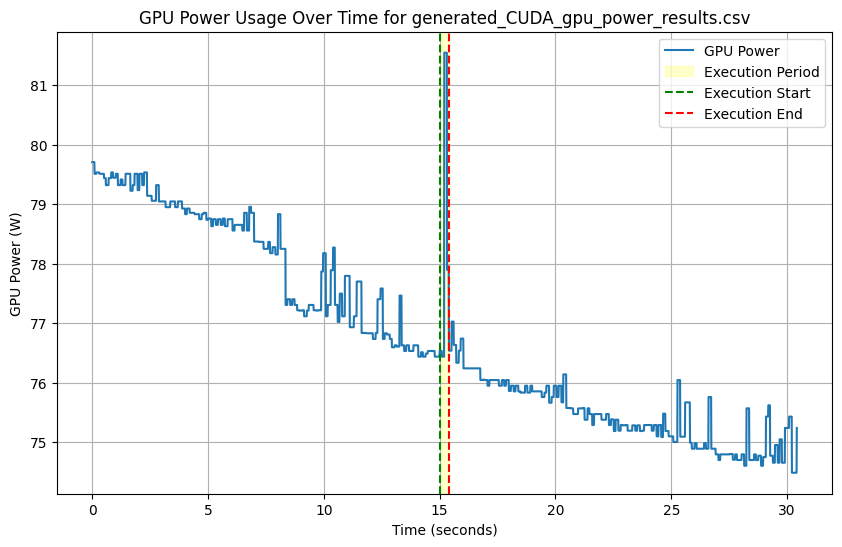

Start time: 15.015 -- End time: 15.406

... Capturing baseline energy consumed for same duration...
Pipeline error | An error occurred: name 'lassi' is not defined

***** Execution failed.
Error message: 
Program exited with return code: -11 Segmentation fault detected.


----- SELF-CORRECTION: 2 -----


----- ERROR SELF-CORRECTION -----

PROMPT (error correction, token count: 8887): [BEGIN CONTEXT KNOWLEDGE] [BEGIN GENERAL CUDA PROGRAMMING CONTEXT] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector addition example used in this chapter and the next can be found in the vectorAdd CUDA sample. 5. 1. Kernels CUDA C++ extends C++ by allowing the programmer to define C++ functions, called kernels, that, when called, are executed N times in parallel by N different CUDA threads, as opposed to only once 

KeyboardInterrupt: 

In [98]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, num_ctx,
    llm_source, use_context, context_knowledge_selection, code_compiler,
    code_compiler_kwds, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()


# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BEGIN GENERAL CUDA PROGRAMMING CONTEXT] " + prompts.get_codeknowledge("cuda") + " [END GENERAL CUDA PROGRAMMING CONTEXT] "
input_context = input_context + " [BEGIN CUDA OPTIMIZATION CONTEXT] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + " [END CUDA OPTIMIZATION CONTEXT] "


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = "HeCBench/" + app_folder_name + "/"
input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

print("\n" + meta_data_file + "\n")


print("\n\n" + color.BOLD + "***** BEGIN PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    num_ctx,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)